<a href="https://colab.research.google.com/github/namgiju/mlprog/blob/main/DL_Diabetes_Binary_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 당뇨병 딥러닝 이진분류 실습
교수님 예제: **NumPy 입력, 원-핫 인코딩, 활성화 함수, 손실 함수, SGD**.

기본 실습은 교수님 슬라이드와 동일한 **Sigmoid + Binary Crossentropy** 방식입니다. 마지막에 원-핫 인코딩을 사용하는 **Softmax + Categorical Crossentropy** 모델도 비교합니다.

## 1. 라이브러리 불러오기

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.optimizers import SGD

tf.keras.utils.set_random_seed(42)

## 2. 구글 드라이브 연결

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
file_path = '/content/drive/MyDrive/diabetes.csv'
df = pd.read_csv(file_path)
print('데이터 크기:', df.shape)
display(df.head())
print('정답 분포:')
print(df['Outcome'].value_counts().sort_index())
print('결측값 수:', df.isna().sum().sum())

데이터 크기: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


정답 분포:
Outcome
0    500
1    268
Name: count, dtype: int64
결측값 수: 0


## 4. X, y 분리 및 NumPy 변환
`Outcome`은 0 또는 1이며 **이진분류** 정답입니다. 입력 특성은 8개입니다.

In [7]:
X = df.drop(columns=['Outcome']).values.astype('float32')
y = df['Outcome'].values.astype('int32')
print('X:', X.shape, 'y:', y.shape)
print('정답 예시:', y[:10])

X: (768, 8) y: (768,)
정답 예시: [1 0 1 0 1 0 1 0 1 1]


## 5. 학습/테스트 분리 및 표준화
데이터 누수를 막기 위해 학습 데이터로만 표준화 기준을 계산합니다.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype('float32')
X_test = scaler.transform(X_test).astype('float32')
print('학습:', X_train.shape, '테스트:', X_test.shape)

학습: (614, 8) 테스트: (154, 8)


## 6. 딥러닝 모델 생성 (Sigmoid 이진분류)
8개 입력 → Dense(32, ReLU) → Dense(16, ReLU) → Dense(1, Sigmoid)

In [9]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Loss Function 및 Optimizer(SGD) 설정
이진 정답이 0/1이고 출력 뉴런이 1개이므로 `binary_crossentropy`를 사용합니다.

In [10]:
model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## 8. 학습 — Forward / Backward Propagation
`fit()` 안에서 순전파 → 손실 계산 → 역전파 → SGD 가중치 업데이트가 반복됩니다.

In [11]:
history = model.fit(
    X_train, y_train,
    epochs=100, batch_size=32,
    validation_split=0.2,
    verbose=0
)
print('학습 완료')

학습 완료


## 9. 모델 평가

In [12]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'테스트 Loss: {loss:.4f}')
print(f'테스트 Accuracy: {accuracy:.4f}')
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)
print(classification_report(y_test, y_pred, zero_division=0))

테스트 Loss: 0.4364
테스트 Accuracy: 0.7857
              precision    recall  f1-score   support

           0       0.80      0.89      0.84       100
           1       0.74      0.59      0.66        54

    accuracy                           0.79       154
   macro avg       0.77      0.74      0.75       154
weighted avg       0.78      0.79      0.78       154



## 10. 학습 곡선

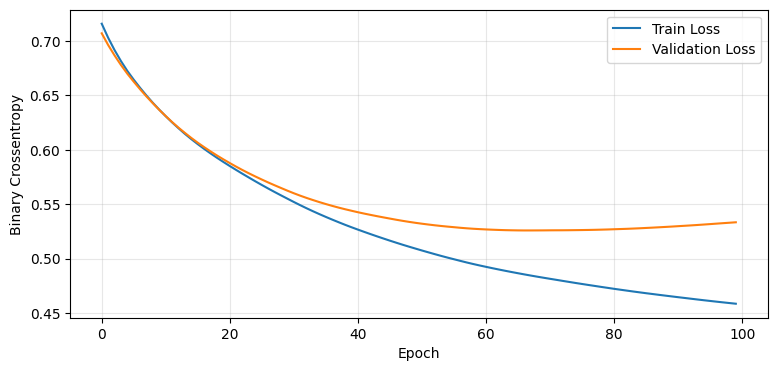

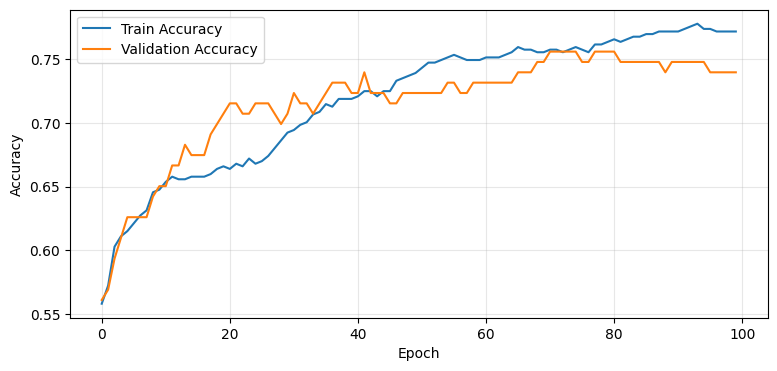

In [13]:
plt.figure(figsize=(9, 4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('Binary Crossentropy'); plt.legend(); plt.grid(alpha=0.3)
plt.show()
plt.figure(figsize=(9, 4))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 11. 혼동행렬

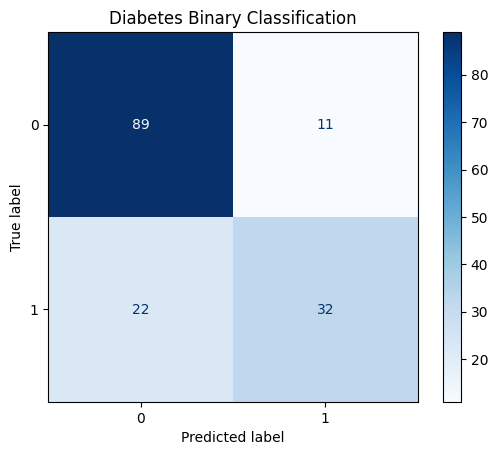

In [14]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['0', '1'], cmap='Blues')
plt.title('Diabetes Binary Classification')
plt.show()

## 12. 원-핫 인코딩 확인 (교수님 방식)
`pd.get_dummies(y).values`를 사용합니다. 이진분류에서 원-핫 인코딩을 쓰면 출력층을 **2개 Softmax**로, 손실 함수를 **Categorical Crossentropy**로 바꿔야 합니다.

In [15]:
Y = pd.get_dummies(pd.Series(y), dtype=int).values
print('원-핫 인코딩 전:', y[:5])
print('원-핫 인코딩 후:\n', Y[:5])
print('Y shape:', Y.shape)
Y_train, Y_test = train_test_split(Y, test_size=0.2, random_state=0, stratify=y)

원-핫 인코딩 전: [1 0 1 0 1]
원-핫 인코딩 후:
 [[0 1]
 [1 0]
 [0 1]
 [1 0]
 [0 1]]
Y shape: (768, 2)


## 13. 원-핫 인코딩 + Softmax 모델 학습 및 비교

In [16]:
tf.keras.utils.set_random_seed(42)
model_onehot = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(2, activation='softmax')
])
model_onehot.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model_onehot.fit(X_train, Y_train, epochs=100, batch_size=32, validation_split=0.2, verbose=0)
loss_onehot, acc_onehot = model_onehot.evaluate(X_test, Y_test, verbose=0)
print(f'Sigmoid + Binary Crossentropy 정확도: {accuracy:.4f}')
print(f'Softmax + One-hot Crossentropy 정확도: {acc_onehot:.4f}')

Sigmoid + Binary Crossentropy 정확도: 0.7857
Softmax + One-hot Crossentropy 정확도: 0.8117


## 14. 핵심 정리
- **Forward Propagation:** 입력을 출력으로 전달해 예측값 생성
- **Loss Function:** 예측과 실제 정답의 차이 계산
- **Backward Propagation:** 손실에 대한 기울기를 역방향으로 계산
- **SGD:** 기울기를 이용해 가중치 업데이트
- **Activation Function:** 은닉층 ReLU, 이진분류 출력 Sigmoid, 원-핫 2클래스 출력 Softmax

**주의:** `pd.get_dummies()`가 딥러닝의 필수 조건은 아닙니다. 정수 0/1 + Sigmoid도 올바른 딥러닝 이진분류입니다.